# Tuning LightGBM and XGBoost for 1-hour-ahead electricity demand forecasting

## Objective

This notebook is separate from the final notebook so that it can:

1. Find the best LightGBM configuration in the defined search space.
2. Find the best XGBoost configuration in the defined search space.
3. Score every trial on the same three rolling folds, September–November 2017.
4. Tune the ensemble weights on out-of-fold predictions.
5. Export the parameter dictionaries and result files to paste back into the final notebook.

The December 2017 final holdout **is not used for tuning or for choosing weights**.

> "Best" here means best among the configurations that were tried. Random search does not guarantee a global optimum, but it is a better fit than a full grid for a dataset that covers only one year.

## 1. Install and import libraries

If the environment does not have the libraries, uncomment and run `%pip install`, then restart the kernel.

In [28]:
# %pip install -U lightgbm xgboost


In [1]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

try:
    import lightgbm as lgb
except ImportError as exc:
    raise ImportError(
        "lightgbm is not installed. Run: %pip install -U lightgbm"
    ) from exc

try:
    import xgboost as xgb
except ImportError as exc:
    raise ImportError(
        "xgboost is not installed. Run: %pip install -U xgboost"
    ) from exc

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

VC_RED = "#D71920"
VC_BLUE = "#4C78A8"
VC_GREEN = "#59A14F"

print(f"LightGBM version: {lgb.__version__}")
print(f"XGBoost version: {xgb.__version__}")

LightGBM version: 4.7.0
XGBoost version: 3.4.1


## 2. Paths and run settings

- `N_TRIALS_LGBM` and `N_TRIALS_XGB` are the number of random configurations to try.
- Run 10 trials for a quick check, then raise it to 30–50 trials.
- Results are checkpointed after every trial.
- When `RESUME_FROM_CHECKPOINT=True`, the notebook skips trials that already finished.

In [2]:
RANDOM_SEED = 42
N_TRIALS_LGBM = 30
N_TRIALS_XGB = 30

MAX_ESTIMATORS = 3000
INNER_VALIDATION_HOURS = 24 * 14
EARLY_STOPPING_ROUNDS = 100
RESUME_FROM_CHECKPOINT = True

FINAL_TEST_START = pd.Timestamp("2017-12-01 00:00:00")
FOLD_MONTHS = [9, 10, 11]

OUTPUT_DIR = Path("output") / "tuning"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LGBM_TRIAL_PATH = OUTPUT_DIR / "lightgbm_tuning_trials.csv"
XGB_TRIAL_PATH = OUTPUT_DIR / "xgboost_tuning_trials.csv"
OOF_PATH = OUTPUT_DIR / "best_models_oof_predictions.csv"
CV_SUMMARY_PATH = OUTPUT_DIR / "best_models_cv_summary.csv"
BEST_CONFIG_PATH = OUTPUT_DIR / "best_model_config.json"

print(f"Checkpoint and results directory: {OUTPUT_DIR.resolve()}")

Checkpoint and results directory: C:\Users\lamda\OneDrive\Desktop\Intro_DS\output\tuning


## 3. Load the modeling-ready data

The notebook looks for `Tetouan_modeling_ready_1h.csv` in `output/`, the current directory, and `data/`, in that order.

In [3]:
candidate_dirs = [Path("output"), Path("."), Path("data")]
model_path = next(
    (
        directory / "Tetouan_modeling_ready_1h.csv"
        for directory in candidate_dirs
        if (directory / "Tetouan_modeling_ready_1h.csv").exists()
    ),
    None,
)

if model_path is None:
    raise FileNotFoundError(
        "Could not find Tetouan_modeling_ready_1h.csv. "
        "Run the data preparation and feature engineering section first."
    )

df_model = (
    pd.read_csv(model_path, parse_dates=["forecast_time"])
    .sort_values("forecast_time")
    .reset_index(drop=True)
)

TARGET_COL = "target_t_plus_1"
NON_FEATURE_COLS = {"forecast_time", TARGET_COL}
feature_columns = [
    column for column in df_model.columns
    if column not in NON_FEATURE_COLS
]

assert TARGET_COL in df_model.columns
assert df_model["forecast_time"].is_monotonic_increasing
assert not df_model["forecast_time"].duplicated().any()
assert df_model[feature_columns + [TARGET_COL]].isna().sum().sum() == 0

development_df = (
    df_model[df_model["forecast_time"] < FINAL_TEST_START]
    .copy()
    .reset_index(drop=True)
)
locked_holdout_df = (
    df_model[df_model["forecast_time"] >= FINAL_TEST_START]
    .copy()
    .reset_index(drop=True)
)

# Rebuild the total_power series by observation timestamp from the modeling-ready data.
origin_time = df_model["forecast_time"] - pd.Timedelta(hours=1)
total_power_by_time = pd.Series(
    df_model["total_power"].to_numpy(),
    index=origin_time,
).sort_index()

print(f"Data source: {model_path}")
print(f"Predictor number: {len(feature_columns)}")
print(
    f"Development: {development_df['forecast_time'].min()} → "
    f"{development_df['forecast_time'].max()} "
    f"({len(development_df):,} lines"
)
print(
    f"Locked holdout: {locked_holdout_df['forecast_time'].min()} → "
    f"{locked_holdout_df['forecast_time'].max()} "
    f"({len(locked_holdout_df):,} lines"
)

Data source: output\Tetouan_modeling_ready_1h.csv
Number of predictors: 54
Development: 2017-01-08 01:00:00 → 2017-11-30 23:00:00 (7,847 lines)
Locked holdout: 2017-12-01 00:00:00 → 2017-12-30 23:00:00 (720 rows)


## 4. Rolling folds and metrics

| Fold | Training | Validation |
|---|---|---|
| 1 | All data before 1 Sep | September |
| 2 | All data before 1 Oct | October |
| 3 | All data before 1 Nov | November |

Trial ranking criteria:

1. Lowest mean WAPE.
2. If those are close, prefer the lower WAPE standard deviation.
3. Then check MASE and bias.

`naive_24h` is the main benchmark used to compute MASE.

In [4]:
fold_defs = []
for month in FOLD_MONTHS:
    validation_start = pd.Timestamp(2017, month, 1)
    validation_end = validation_start + pd.offsets.MonthBegin(1)
    fold_defs.append((
        f"Fold_{month:02d}_2017",
        validation_start,
        validation_end,
    ))


def regression_metrics(y_true, y_pred, naive_mae=None):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    error = y_true - y_pred

    mae = np.abs(error).mean()
    rmse = np.sqrt(np.mean(error ** 2))
    wape = np.abs(error).sum() / np.abs(y_true).sum() * 100
    bias = np.mean(y_pred - y_true)
    mase = mae / naive_mae if naive_mae not in (None, 0) else np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE_%": wape,
        "MASE": mase,
        "Bias": bias,
    }


def naive_forecasts(forecast_time):
    def lagged(hours):
        timestamp = forecast_time - pd.Timedelta(hours=hours)
        return total_power_by_time.reindex(timestamp).to_numpy()

    predictions = {
        "naive_1h": lagged(1),
        "naive_24h": lagged(24),
        "naive_168h": lagged(168),
    }
    four_week_values = np.column_stack([
        lagged(168 * week) for week in (1, 2, 3, 4)
    ])
    predictions["naive_avg4w"] = np.nanmean(four_week_values, axis=1)
    return predictions


fold_summary = []
for fold_name, val_start, val_end in fold_defs:
    train_rows = int((development_df["forecast_time"] < val_start).sum())
    val_rows = int((
        (development_df["forecast_time"] >= val_start)
        & (development_df["forecast_time"] < val_end)
    ).sum())
    fold_summary.append({
        "fold": fold_name,
        "train_rows": train_rows,
        "validation_rows": val_rows,
        "validation_start": val_start,
        "validation_end_exclusive": val_end,
    })

display(pd.DataFrame(fold_summary))


,fold,train_rows,validation_rows,validation_start,validation_end_exclusive
0,Fold_09_2017,5663,720,2017-09-01,2017-10-01
1,Fold_10_2017,6383,744,2017-10-01,2017-11-01
2,Fold_11_2017,7127,720,2017-11-01,2017-12-01


## 5. Base configuration and search space

The number of trees is not tuned directly. `n_estimators=3000` is an upper bound, and early stopping picks a suitable number of trees inside each fold.

LightGBM search focuses on `num_leaves`, `max_depth`, `min_child_samples`, sampling, and regularization. XGBoost search focuses on `max_depth`, `min_child_weight`, `gamma`, sampling, and regularization.

In [5]:
LGBM_BASE_PARAMS = dict(
    objective="regression",
    n_estimators=MAX_ESTIMATORS,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbosity=-1,
)

XGB_BASE_PARAMS = dict(
    objective="reg:squarederror",
    eval_metric="mae",
    n_estimators=MAX_ESTIMATORS,
    tree_method="hist",
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbosity=0,
)

LGBM_SPACE = {
    "learning_rate": [0.02, 0.03, 0.05],
    "num_leaves": [15, 31, 63],
    "max_depth": [-1, 5, 7, 9],
    "min_child_samples": [20, 30, 50, 100],
    "min_split_gain": [0.0, 0.01, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "reg_alpha": [0.0, 0.1, 1.0],
    "reg_lambda": [0.0, 1.0, 5.0, 10.0],
}

XGB_SPACE = {
    "learning_rate": [0.02, 0.03, 0.05],
    "max_depth": [3, 4, 5, 6, 8],
    "min_child_weight": [1, 3, 5, 10, 20],
    "gamma": [0.0, 0.01, 0.1, 0.5],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "reg_alpha": [0.0, 0.1, 1.0],
    "reg_lambda": [1.0, 5.0, 10.0],
}


In [6]:
def choose(rng, values):
    return values[int(rng.integers(0, len(values)))]


def sample_lgbm_candidates(n_trials, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    candidates = []
    seen = set()

    while len(candidates) < n_trials:
        max_depth = choose(rng, LGBM_SPACE["max_depth"])
        allowed_leaves = [
            leaves
            for leaves in LGBM_SPACE["num_leaves"]
            if max_depth <= 0 or leaves <= 2 ** max_depth
        ]
        subsample = choose(rng, LGBM_SPACE["subsample"])
        params = {
            "learning_rate": choose(rng, LGBM_SPACE["learning_rate"]),
            "num_leaves": choose(rng, allowed_leaves),
            "max_depth": max_depth,
            "min_child_samples": choose(rng, LGBM_SPACE["min_child_samples"]),
            "min_split_gain": choose(rng, LGBM_SPACE["min_split_gain"]),
            "subsample": subsample,
            "subsample_freq": 1 if subsample < 1 else 0,
            "colsample_bytree": choose(rng, LGBM_SPACE["colsample_bytree"]),
            "reg_alpha": choose(rng, LGBM_SPACE["reg_alpha"]),
            "reg_lambda": choose(rng, LGBM_SPACE["reg_lambda"]),
        }
        key = json.dumps(params, sort_keys=True)
        if key not in seen:
            seen.add(key)
            candidates.append(params)

    return candidates


def sample_xgb_candidates(n_trials, seed=RANDOM_SEED + 1):
    rng = np.random.default_rng(seed)
    candidates = []
    seen = set()

    while len(candidates) < n_trials:
        params = {
            name: choose(rng, values)
            for name, values in XGB_SPACE.items()
        }
        key = json.dumps(params, sort_keys=True)
        if key not in seen:
            seen.add(key)
            candidates.append(params)

    return candidates


lgbm_candidates = sample_lgbm_candidates(N_TRIALS_LGBM)
xgb_candidates = sample_xgb_candidates(N_TRIALS_XGB)

print(f"LightGBM candidates: {len(lgbm_candidates)}")
print(f"XGBoost candidates: {len(xgb_candidates)}")
display(pd.DataFrame(lgbm_candidates).head())
display(pd.DataFrame(xgb_candidates).head())


LightGBM candidates: 30
XGBoost candidates: 30


,learning_rate,num_leaves,max_depth,min_child_samples,min_split_gain,subsample,subsample_freq,colsample_bytree,reg_alpha,reg_lambda
0,0.0300,31,-1,30,0.1000,1.0000,0,0.7000,1.0000,0.0000
1,0.0500,63,-1,100,0.1000,0.9000,1,1.0000,0.1000,0.0000
2,0.0300,31,9,20,0.1000,0.8000,1,1.0000,0.1000,1.0000
3,0.0300,31,9,20,0.0000,0.9000,1,0.9000,1.0000,0.0000
4,0.0200,31,9,20,0.1000,1.0000,0,0.9000,0.1000,0.0000


,learning_rate,max_depth,min_child_weight,gamma,subsample,colsample_bytree,reg_alpha,reg_lambda
0,0.0300,6,5,0.0000,0.9000,0.7000,0.0000,10.0000
1,0.0300,5,20,0.0000,1.0000,1.0000,0.1000,1.0000
2,0.0200,5,10,0.0100,0.7000,1.0000,0.1000,10.0000
3,0.0200,4,10,0.0100,1.0000,0.8000,0.1000,1.0000
4,0.0300,4,5,0.5000,0.7000,1.0000,0.1000,5.0000


## 6. Training function with inner temporal validation

Inside each outer fold:

1. Hold out the last 14 days of the training fold as inner validation.
2. Use early stopping to choose the number of trees.
3. Refit the model on the full training fold with that number of trees.
4. Forecast the outer validation month.

The outer validation set does not take part in choosing the number of trees.

In [7]:
def temporal_inner_split(train_df, validation_hours=INNER_VALIDATION_HOURS):
    if len(train_df) <= validation_hours * 2:
        raise ValueError("The training fold is too short to build an inner validation set.")
    return (
        train_df.iloc[:-validation_hours].copy(),
        train_df.iloc[-validation_hours:].copy(),
    )


def fit_predict_lightgbm(train_df, val_df, trial_params):
    inner_train, inner_val = temporal_inner_split(train_df)
    params = {**LGBM_BASE_PARAMS, **trial_params}

    selector = lgb.LGBMRegressor(**params)
    selector.fit(
        inner_train[feature_columns],
        inner_train[TARGET_COL],
        eval_set=[(inner_val[feature_columns], inner_val[TARGET_COL])],
        eval_metric="l1",
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=EARLY_STOPPING_ROUNDS,
                verbose=False,
            )
        ],
    )

    best_n_estimators = int(
        selector.best_iteration_ or MAX_ESTIMATORS
    )
    final_params = {**params, "n_estimators": best_n_estimators}
    final_model = lgb.LGBMRegressor(**final_params)
    final_model.fit(train_df[feature_columns], train_df[TARGET_COL])

    prediction = final_model.predict(val_df[feature_columns])
    return prediction, best_n_estimators, final_model


def fit_predict_xgboost(train_df, val_df, trial_params):
    inner_train, inner_val = temporal_inner_split(train_df)
    params = {**XGB_BASE_PARAMS, **trial_params}

    selector = xgb.XGBRegressor(
        **params,
        early_stopping_rounds=EARLY_STOPPING_ROUNDS,
    )
    selector.fit(
        inner_train[feature_columns],
        inner_train[TARGET_COL],
        eval_set=[(inner_val[feature_columns], inner_val[TARGET_COL])],
        verbose=False,
    )

    best_iteration = getattr(selector, "best_iteration", None)
    best_n_estimators = (
        int(best_iteration) + 1
        if best_iteration is not None
        else MAX_ESTIMATORS
    )
    final_params = {**params, "n_estimators": best_n_estimators}
    final_model = xgb.XGBRegressor(**final_params)
    final_model.fit(
        train_df[feature_columns],
        train_df[TARGET_COL],
        verbose=False,
    )

    prediction = final_model.predict(val_df[feature_columns])
    return prediction, best_n_estimators, final_model

## 7. Evaluate one trial on three rolling folds

The function returns per-fold metrics, the mean metrics, the WAPE standard deviation, and the number of trees chosen by early stopping.

In [8]:
def evaluate_model_params(model_name, trial_params, return_predictions=False):
    fold_rows = []
    prediction_frames = []
    best_iterations = []

    for fold_name, val_start, val_end in fold_defs:
        train_fold = (
            development_df[development_df["forecast_time"] < val_start]
            .copy()
            .reset_index(drop=True)
        )
        val_fold = (
            development_df[
                (development_df["forecast_time"] >= val_start)
                & (development_df["forecast_time"] < val_end)
            ]
            .copy()
            .reset_index(drop=True)
        )

        y_val = val_fold[TARGET_COL].to_numpy()
        naive_preds = naive_forecasts(val_fold["forecast_time"])
        naive_mae = regression_metrics(
            y_val,
            naive_preds["naive_24h"],
        )["MAE"]

        if model_name == "LightGBM":
            prediction, best_n, _ = fit_predict_lightgbm(
                train_fold,
                val_fold,
                trial_params,
            )
        elif model_name == "XGBoost":
            prediction, best_n, _ = fit_predict_xgboost(
                train_fold,
                val_fold,
                trial_params,
            )
        else:
            raise ValueError(f"Unsupported model: {model_name}")

        metrics = regression_metrics(y_val, prediction, naive_mae)
        fold_rows.append({
            "fold": fold_name,
            "best_n_estimators": best_n,
            **metrics,
        })
        best_iterations.append(best_n)

        if return_predictions:
            frame = val_fold[["forecast_time", TARGET_COL]].copy()
            frame["fold"] = fold_name
            frame[model_name] = prediction
            for naive_name, naive_prediction in naive_preds.items():
                frame[naive_name] = naive_prediction
            prediction_frames.append(frame)

    fold_result = pd.DataFrame(fold_rows)
    aggregate = {
        "WAPE_mean": fold_result["WAPE_%"].mean(),
        "WAPE_std": fold_result["WAPE_%"].std(),
        "MAE_mean": fold_result["MAE"].mean(),
        "RMSE_mean": fold_result["RMSE"].mean(),
        "MASE_mean": fold_result["MASE"].mean(),
        "Bias_mean": fold_result["Bias"].mean(),
        "best_n_estimators_median": int(np.median(best_iterations)),
        "best_n_estimators_min": int(np.min(best_iterations)),
        "best_n_estimators_max": int(np.max(best_iterations)),
    }

    for _, row in fold_result.iterrows():
        fold_key = row["fold"].replace("Fold_", "").lower()
        aggregate[f"{fold_key}_WAPE"] = row["WAPE_%"]
        aggregate[f"{fold_key}_MASE"] = row["MASE"]
        aggregate[f"{fold_key}_Bias"] = row["Bias"]
        aggregate[f"{fold_key}_best_n"] = int(row["best_n_estimators"])

    predictions = (
        pd.concat(prediction_frames, ignore_index=True)
        if return_predictions
        else None
    )
    return aggregate, fold_result, predictions

## 8. Run random search and checkpoint

Each trial is saved as soon as it finishes. If a trial fails, the error is recorded and the notebook continues with the next trial.

Runtime depends on the CPU and the number of trials. With 30 trials per model, the total number of fits is large: each trial runs three folds, and each fold has an early-stopping step plus a refit.

In [9]:
def load_checkpoint(path):
    if RESUME_FROM_CHECKPOINT and path.exists():
        result = pd.read_csv(path)
        print(f"Loaded checkpoint {path}: {len(result)} trial")
        return result
    return pd.DataFrame()


def run_random_search(model_name, candidates, checkpoint_path):
    results = load_checkpoint(checkpoint_path)
    existing_params = {}
    completed_ids = set()
    if not results.empty and "trial_id" in results.columns:
        for _, existing_row in results.iterrows():
            existing_id = int(existing_row["trial_id"])
            existing_params[existing_id] = existing_row["params_json"]
            if existing_row.get("status") == "ok":
                completed_ids.add(existing_id)

    for trial_id, trial_params in enumerate(candidates, start=1):
        params_json = json.dumps(trial_params, sort_keys=True)
        if (
            trial_id in existing_params
            and existing_params[trial_id] != params_json
        ):
            raise ValueError(
                f"Checkpoint {checkpoint_path} does not match the current search space "
                f"at trial {trial_id}. Change the output directory or delete the old checkpoint."
            )
        if trial_id in completed_ids:
            continue

        # Allow a previously failed trial to be retried without writing a duplicate row.
        if not results.empty and "trial_id" in results.columns:
            results = results[
                results["trial_id"].astype(int) != trial_id
            ].copy()

        started = time.perf_counter()
        row = {
            "trial_id": trial_id,
            "model": model_name,
            "params_json": params_json,
        }

        try:
            aggregate, _, _ = evaluate_model_params(
                model_name,
                trial_params,
                return_predictions=False,
            )
            row.update({
                "status": "ok",
                **aggregate,
                "error": "",
            })
        except Exception as exc:
            row.update({
                "status": "failed",
                "error": repr(exc),
            })

        row["runtime_seconds"] = time.perf_counter() - started
        results = pd.concat(
            [results, pd.DataFrame([row])],
            ignore_index=True,
        )
        results.to_csv(checkpoint_path, index=False)

        if row["status"] == "ok":
            print(
                f"{model_name} trial {trial_id}/{len(candidates)} — "
                f"WAPE={row['WAPE_mean']:.4f}% — "
                f"{row['runtime_seconds']:.1f}s"
            )
        else:
            print(
                f"{model_name} trial {trial_id}/{len(candidates)} — FAILED: "
                f"{row['error']}"
            )

    return results.sort_values("trial_id").reset_index(drop=True)

In [10]:
lgbm_tuning_results = run_random_search(
    "LightGBM",
    lgbm_candidates,
    LGBM_TRIAL_PATH,
)

xgb_tuning_results = run_random_search(
    "XGBoost",
    xgb_candidates,
    XGB_TRIAL_PATH,
)

print("Random search complete.")

Loaded checkpoint output\tuning\lightgbm_tuning_trials.csv: 30 trial
Loaded checkpoint output\tuning\xgboost_tuning_trials.csv: 30 trial
Random search complete.


## 9. Select the best parameter set

Successful trials are sorted by:

1. Mean WAPE, ascending.
2. WAPE standard deviation, ascending.
3. Mean MASE, ascending.

December does not appear in the ranking.

In [11]:
def successful_trials(results, model_name):
    successful = results[results["status"] == "ok"].copy()
    if successful.empty:
        failed = results[["trial_id", "error"]].tail(5)
        display(failed)
        raise RuntimeError(f"No trial for {model_name} completed successfully.")

    return successful.sort_values(
        ["WAPE_mean", "WAPE_std", "MASE_mean"],
        ascending=True,
    ).reset_index(drop=True)


lgbm_ranking = successful_trials(lgbm_tuning_results, "LightGBM")
xgb_ranking = successful_trials(xgb_tuning_results, "XGBoost")

best_lgbm_row = lgbm_ranking.iloc[0]
best_xgb_row = xgb_ranking.iloc[0]

BEST_LGBM_TRIAL_PARAMS = json.loads(best_lgbm_row["params_json"])
BEST_XGB_TRIAL_PARAMS = json.loads(best_xgb_row["params_json"])

BEST_LGBM_PARAMS = {
    **LGBM_BASE_PARAMS,
    **BEST_LGBM_TRIAL_PARAMS,
    "n_estimators": int(best_lgbm_row["best_n_estimators_median"]),
}
BEST_XGB_PARAMS = {
    **XGB_BASE_PARAMS,
    **BEST_XGB_TRIAL_PARAMS,
    "n_estimators": int(best_xgb_row["best_n_estimators_median"]),
}

ranking_columns = [
    "trial_id",
    "WAPE_mean",
    "WAPE_std",
    "MASE_mean",
    "Bias_mean",
    "best_n_estimators_median",
    "runtime_seconds",
    "params_json",
]

print("Top 10 LightGBM trials:")
display(lgbm_ranking[ranking_columns].head(10))

print("Top 10 XGBoost trials:")
display(xgb_ranking[ranking_columns].head(10))

print("BEST_LGBM_PARAMS =")
print(json.dumps(BEST_LGBM_PARAMS, indent=4, ensure_ascii=False))

print("\nBEST_XGB_PARAMS =")
print(json.dumps(BEST_XGB_PARAMS, indent=4, ensure_ascii=False))

Top 10 LightGBM trials:


,trial_id,WAPE_mean,WAPE_std,MASE_mean,Bias_mean,best_n_estimators_median,runtime_seconds,params_json
0,25,2.1600,0.3155,0.6572,215.5034,1184,14.1201,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0..."
1,3,2.1616,0.3375,0.6536,178.5026,670,5.6407,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.0..."
2,27,2.1674,0.4004,0.6612,309.7525,1272,5.2000,"{""colsample_bytree"": 0.7, ""learning_rate"": 0.0..."
3,5,2.1787,0.4148,0.6563,204.9544,1164,6.0238,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0..."
4,16,2.1847,0.3413,0.6645,358.9902,1639,7.6874,"{""colsample_bytree"": 0.7, ""learning_rate"": 0.0..."
5,9,2.1885,0.4530,0.6670,289.3365,767,4.0281,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0..."
6,8,2.1965,0.3869,0.6644,195.9067,1302,10.3247,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0..."
7,23,2.1979,0.4034,0.6666,270.6376,1120,4.5413,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0..."
8,10,2.1991,0.3400,0.6706,426.0451,954,4.6322,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0..."
9,26,2.2016,0.4639,0.6675,165.5137,917,5.3822,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.0..."


Top 10 XGBoost trials:


,trial_id,WAPE_mean,WAPE_std,MASE_mean,Bias_mean,best_n_estimators_median,runtime_seconds,params_json
0,11,2.1168,0.3770,0.6429,136.0428,2721,36.8157,"{""colsample_bytree"": 0.9, ""gamma"": 0.0, ""learn..."
1,23,2.1223,0.3814,0.6409,112.3476,686,14.1990,"{""colsample_bytree"": 1.0, ""gamma"": 0.0, ""learn..."
2,5,2.1261,0.3188,0.6469,169.5037,2286,29.3110,"{""colsample_bytree"": 1.0, ""gamma"": 0.5, ""learn..."
3,10,2.1321,0.3188,0.6480,278.0746,2042,27.1437,"{""colsample_bytree"": 0.8, ""gamma"": 0.1, ""learn..."
4,3,2.1509,0.3242,0.6556,273.8624,1719,31.9250,"{""colsample_bytree"": 1.0, ""gamma"": 0.01, ""lear..."
5,15,2.1566,0.4146,0.6546,164.3007,1484,24.4346,"{""colsample_bytree"": 1.0, ""gamma"": 0.1, ""learn..."
6,21,2.1608,0.3885,0.6586,186.6070,1568,21.9172,"{""colsample_bytree"": 1.0, ""gamma"": 0.01, ""lear..."
7,12,2.1676,0.4246,0.6577,249.5545,598,15.0116,"{""colsample_bytree"": 0.9, ""gamma"": 0.0, ""learn..."
8,24,2.1694,0.2801,0.6603,288.6158,1120,20.8068,"{""colsample_bytree"": 0.8, ""gamma"": 0.01, ""lear..."
9,29,2.1697,0.3236,0.6615,283.1860,1030,22.6773,"{""colsample_bytree"": 1.0, ""gamma"": 0.1, ""learn..."


BEST_LGBM_PARAMS =
{
    "objective": "regression",
    "n_estimators": 1184,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1,
    "colsample_bytree": 0.9,
    "learning_rate": 0.03,
    "max_depth": -1,
    "min_child_samples": 20,
    "min_split_gain": 0.01,
    "num_leaves": 63,
    "reg_alpha": 0.0,
    "reg_lambda": 5.0,
    "subsample": 0.7,
    "subsample_freq": 1
}

BEST_XGB_PARAMS =
{
    "objective": "reg:squarederror",
    "eval_metric": "mae",
    "n_estimators": 2721,
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": 0,
    "colsample_bytree": 0.9,
    "gamma": 0.0,
    "learning_rate": 0.02,
    "max_depth": 5,
    "min_child_weight": 3,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0,
    "subsample": 0.9
}


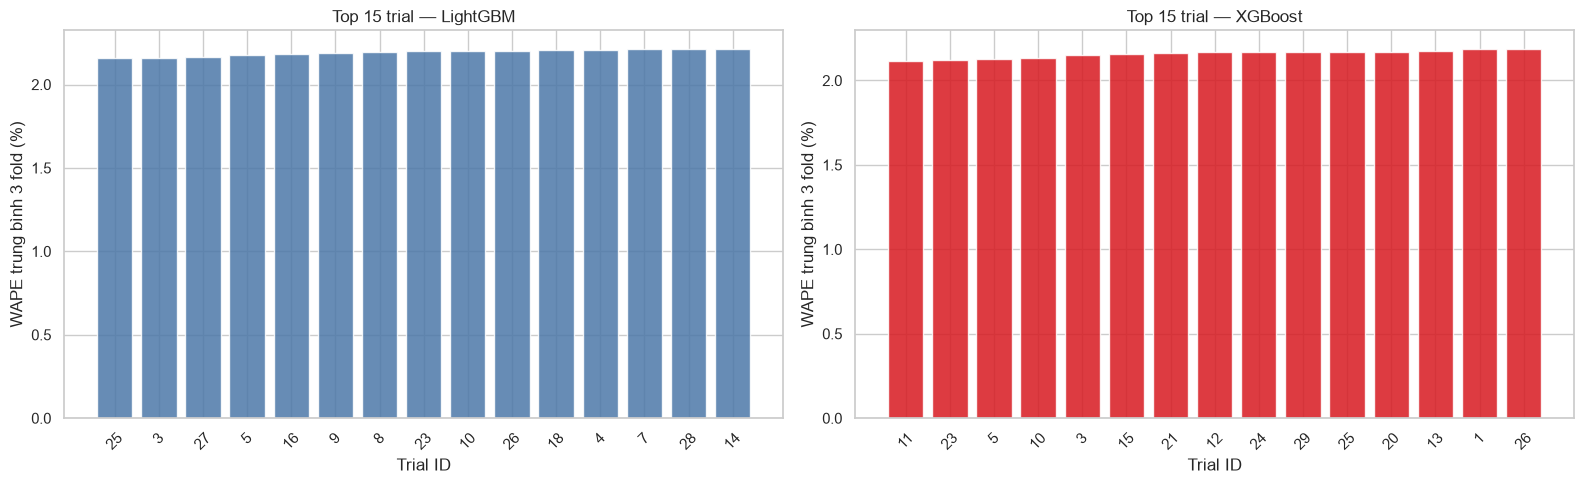

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, ranking, title, color in [
    (axes[0], lgbm_ranking, "LightGBM", VC_BLUE),
    (axes[1], xgb_ranking, "XGBoost", VC_RED),
]:
    plot_data = ranking.head(15).copy()
    ax.bar(
        plot_data["trial_id"].astype(str),
        plot_data["WAPE_mean"],
        color=color,
        alpha=0.85,
    )
    ax.set_title(f"Top 15 trial — {title}")
    ax.set_xlabel("Trial ID")
    ax.set_ylabel("Mean WAPE across 3 folds (%)")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 10. Refit the two best configurations and tune the ensemble

The two best models are refit to produce out-of-fold forecasts. Ensemble weights are searched on a grid from 0% to 100% LightGBM, in steps of 5%.

The ensemble is recommended only if:

- Both models have a weight greater than 0.
- WAPE improves by at least 0.5% relative to the best single model.

In [14]:
lgbm_aggregate, lgbm_fold_result, lgbm_oof = evaluate_model_params(
    "LightGBM",
    BEST_LGBM_TRIAL_PARAMS,
    return_predictions=True,
)
xgb_aggregate, xgb_fold_result, xgb_oof = evaluate_model_params(
    "XGBoost",
    BEST_XGB_TRIAL_PARAMS,
    return_predictions=True,
)

oof_predictions = lgbm_oof.merge(
    xgb_oof[["forecast_time", "fold", "XGBoost"]],
    on=["forecast_time", "fold"],
    how="inner",
    validate="one_to_one",
)

y_oof = oof_predictions[TARGET_COL].to_numpy()
lgbm_pred_oof = oof_predictions["LightGBM"].to_numpy()
xgb_pred_oof = oof_predictions["XGBoost"].to_numpy()

weight_rows = []
for weight_lgbm in np.arange(0.0, 1.0001, 0.05):
    weight_xgb = 1.0 - weight_lgbm
    prediction = (
        weight_lgbm * lgbm_pred_oof
        + weight_xgb * xgb_pred_oof
    )
    metrics = regression_metrics(y_oof, prediction)
    weight_rows.append({
        "weight_lgbm": weight_lgbm,
        "weight_xgb": weight_xgb,
        "WAPE_%": metrics["WAPE_%"],
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "Bias": metrics["Bias"],
    })

ensemble_weight_results = pd.DataFrame(weight_rows)
best_weight_row = ensemble_weight_results.loc[
    ensemble_weight_results["WAPE_%"].idxmin()
]

BEST_LGBM_WEIGHT = float(best_weight_row["weight_lgbm"])
BEST_XGB_WEIGHT = float(best_weight_row["weight_xgb"])

oof_predictions["Ensemble"] = (
    BEST_LGBM_WEIGHT * oof_predictions["LightGBM"]
    + BEST_XGB_WEIGHT * oof_predictions["XGBoost"]
)

print(
    f"Best weights: LightGBM={BEST_LGBM_WEIGHT:.0%}, "
    f"XGBoost={BEST_XGB_WEIGHT:.0%}"
)
display(ensemble_weight_results.sort_values("WAPE_%").head(10))

Best weights: LightGBM=35%, XGBoost=65%


,weight_lgbm,weight_xgb,WAPE_%,MAE,RMSE,Bias
7,0.3500,0.6500,2.0925,"1,403.2575","2,024.7554",161.8612
6,0.3000,0.7000,2.0926,"1,403.3387","2,021.1214",157.7696
8,0.4000,0.6000,2.0930,"1,403.5966","2,029.0994",165.9529
5,0.2500,0.7500,2.0934,"1,403.8712","2,018.2011",153.6779
9,0.4500,0.5500,2.0942,"1,404.3654","2,034.1488",170.0445
4,0.2000,0.8000,2.0949,"1,404.8637","2,015.9978",149.5863
10,0.5000,0.5000,2.0960,"1,405.5732","2,039.8984",174.1362
3,0.1500,0.8500,2.0970,"1,406.2500","2,014.5137",145.4947
11,0.5500,0.4500,2.0985,"1,407.2857","2,046.3423",178.2278
2,0.1000,0.9000,2.0999,"1,408.2344","2,013.7505",141.4030


## 11. Compare Seasonal Naive, the two best models, and the ensemble

The recommended model is chosen from the rolling backtest. If every machine-learning model is worse than Seasonal Naive, the notebook keeps the simple baseline.

In [15]:
MODEL_ORDER = [
    "naive_1h",
    "naive_24h",
    "naive_168h",
    "naive_avg4w",
    "LightGBM",
    "XGBoost",
    "Ensemble",
]

comparison_rows = []
for fold_name, _, _ in fold_defs:
    segment = oof_predictions[oof_predictions["fold"] == fold_name]
    y_fold = segment[TARGET_COL].to_numpy()
    naive_mae = regression_metrics(
        y_fold,
        segment["naive_24h"].to_numpy(),
    )["MAE"]

    for model_name in MODEL_ORDER:
        metrics = regression_metrics(
            y_fold,
            segment[model_name].to_numpy(),
            naive_mae,
        )
        comparison_rows.append({
            "fold": fold_name,
            "model": model_name,
            **metrics,
        })

comparison_by_fold = pd.DataFrame(comparison_rows)
cv_summary = (
    comparison_by_fold
    .groupby("model")[["MAE", "RMSE", "WAPE_%", "MASE", "Bias"]]
    .mean()
    .reindex(MODEL_ORDER)
)
cv_summary["WAPE_std"] = (
    comparison_by_fold.groupby("model")["WAPE_%"].std().reindex(MODEL_ORDER)
)

best_individual_name = cv_summary.loc[
    ["LightGBM", "XGBoost"], "WAPE_%"
].idxmin()
best_individual_wape = cv_summary.loc[best_individual_name, "WAPE_%"]
ensemble_wape = cv_summary.loc["Ensemble", "WAPE_%"]
ensemble_gain_pct = (
    (best_individual_wape - ensemble_wape)
    / best_individual_wape
    * 100
)

MIN_ENSEMBLE_GAIN_PCT = 0.5
ensemble_uses_both = 0 < BEST_LGBM_WEIGHT < 1

if ensemble_uses_both and ensemble_gain_pct >= MIN_ENSEMBLE_GAIN_PCT:
    recommended_ml_name = "Ensemble"
else:
    recommended_ml_name = best_individual_name

baseline_names = [
    "naive_1h",
    "naive_24h",
    "naive_168h",
    "naive_avg4w",
]
best_baseline_name = cv_summary.loc[baseline_names, "WAPE_%"].idxmin()

if (
    cv_summary.loc[recommended_ml_name, "WAPE_%"]
    < cv_summary.loc[best_baseline_name, "WAPE_%"]
):
    SELECTED_MODEL = recommended_ml_name
else:
    SELECTED_MODEL = best_baseline_name

print("Mean results across the 3 rolling folds:")
display(cv_summary.round(4))
print(f"Best single ML model: {best_individual_name}")
print(f"Ensemble relative gain: {ensemble_gain_pct:.4f}%")
print(f"ML candidates are recommended to: {recommended_ml_name}")
print(f"Best Seasonal Naive: {best_baseline_name}")
print(f"Best model under the selection rule: {SELECTED_MODEL}")

Mean results across the 3 rolling folds:


,MAE,RMSE,WAPE_%,MASE,Bias,WAPE_std
model,,,,,,
naive_1h,"4,173.1099","5,660.8885",6.2237,1.8971,5.2374,0.0446
naive_24h,"2,237.6825","3,255.4866",3.3327,1.0000,38.7885,0.5313
naive_168h,"2,874.5609","4,086.8662",4.2676,1.2248,911.2252,2.4836
naive_avg4w,"4,406.0579","5,650.4793",6.5082,1.8188,"3,504.1101",5.5875
LightGBM,"1,445.3091","2,124.0862",2.1600,0.6572,215.5034,0.3155
XGBoost,"1,415.9335","2,001.8249",2.1168,0.6429,136.0428,0.3770
Ensemble,"1,405.4873","2,011.8491",2.1011,0.6385,163.8524,0.3623


Best single ML model: XGBoost
Ensemble relative gain: 0.7402%
Recommended ML candidate: Ensemble
Best Seasonal Naive: naive_24h
Best model under the selection rule: Ensemble


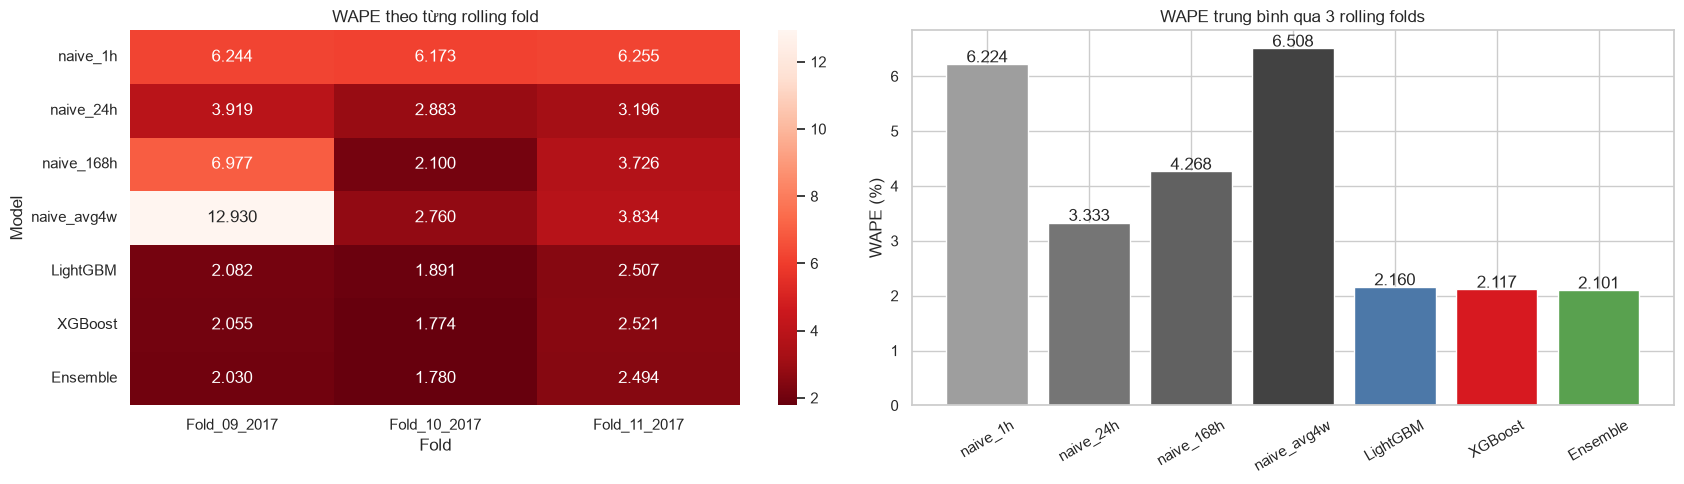

In [16]:
fold_pivot = (
    comparison_by_fold
    .pivot(index="model", columns="fold", values="WAPE_%")
    .reindex(MODEL_ORDER)
)

fig, axes = plt.subplots(1, 2, figsize=(17, 5))

sns.heatmap(
    fold_pivot,
    annot=True,
    fmt=".3f",
    cmap="Reds_r",
    ax=axes[0],
)
axes[0].set_title("WAPE by rolling fold")
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("Model")

colors = [
    "#9E9E9E",
    "#757575",
    "#616161",
    "#424242",
    VC_BLUE,
    VC_RED,
    VC_GREEN,
]
axes[1].bar(
    cv_summary.index,
    cv_summary["WAPE_%"],
    color=colors,
)
axes[1].set_title("Mean WAPE across the 3 rolling folds")
axes[1].set_ylabel("WAPE (%)")
axes[1].tick_params(axis="x", rotation=30)

for index, value in enumerate(cv_summary["WAPE_%"]):
    axes[1].text(index, value + 0.03, f"{value:.3f}", ha="center")

plt.tight_layout()
plt.show()

## 12. Check peak magnitude and peak timing on out-of-fold predictions

Peak metrics are a secondary check. They do not replace WAPE. For each day, the notebook compares the peak value and the peak hour between actual and forecast.

In [17]:
def daily_peak_metrics(frame, prediction_col):
    peak_data = frame[["forecast_time", TARGET_COL, prediction_col]].copy()
    peak_data["date"] = peak_data["forecast_time"].dt.date
    peak_data["hour"] = peak_data["forecast_time"].dt.hour

    rows = []
    for date_value, group in peak_data.groupby("date"):
        actual_index = group[TARGET_COL].idxmax()
        prediction_index = group[prediction_col].idxmax()

        actual_peak = group.loc[actual_index, TARGET_COL]
        predicted_peak = group.loc[prediction_index, prediction_col]
        actual_hour = int(group.loc[actual_index, "hour"])
        predicted_hour = int(group.loc[prediction_index, "hour"])

        hour_difference = abs(predicted_hour - actual_hour)
        timing_error = min(hour_difference, 24 - hour_difference)

        rows.append({
            "date": date_value,
            "actual_peak": actual_peak,
            "predicted_peak": predicted_peak,
            "magnitude_error": predicted_peak - actual_peak,
            "timing_error_hours": timing_error,
        })

    daily = pd.DataFrame(rows)
    return {
        "Peak_MAE": daily["magnitude_error"].abs().mean(),
        "Peak_MAPE_%": (
            daily["magnitude_error"].abs()
            / daily["actual_peak"]
            * 100
        ).mean(),
        "Peak_Bias": daily["magnitude_error"].mean(),
        "Peak_Timing_MAE_hours": daily["timing_error_hours"].mean(),
        "Peak_Timing_within_1h": (
            daily["timing_error_hours"] <= 1
        ).mean(),
    }


peak_summary = pd.DataFrame({
    model_name: daily_peak_metrics(oof_predictions, model_name)
    for model_name in MODEL_ORDER
}).T

display(peak_summary.round(4))


,Peak_MAE,Peak_MAPE_%,Peak_Bias,Peak_Timing_MAE_hours,Peak_Timing_within_1h
naive_1h,0.0000,0.0000,0.0000,1.0000,1.0000
naive_24h,"2,333.1564",2.5525,67.7162,0.2418,1.0000
naive_168h,"2,911.3889",3.1876,"1,140.8805",0.1978,1.0000
naive_avg4w,"4,816.5136",5.2345,"4,554.1272",0.3846,1.0000
LightGBM,"1,651.5631",1.8137,"1,182.2979",0.3187,1.0000
XGBoost,"1,823.3483",2.0131,"1,375.5409",0.3736,1.0000
Ensemble,"1,746.5343",1.9255,"1,293.0994",0.3516,1.0000


## 13. Export results for the final notebook

The notebook exports:

- The full LightGBM and XGBoost trial history.
- Out-of-fold predictions from the two best configurations.
- The CV summary table.
- A JSON file with the best parameters, ensemble weights, and the recommended model.

`n_estimators` in the JSON is the median of the best tree counts across the three folds. When this is copied into the final notebook, keep early stopping if a valid inner validation set is available.

In [18]:
best_config = {
    "selection_basis": {
        "primary_metric": "WAPE_mean_3_rolling_folds",
        "folds": [name for name, _, _ in fold_defs],
        "final_holdout_used_for_tuning": False,
    },
    "best_lightgbm_params": BEST_LGBM_PARAMS,
    "best_xgboost_params": BEST_XGB_PARAMS,
    "ensemble": {
        "weight_lightgbm": BEST_LGBM_WEIGHT,
        "weight_xgboost": BEST_XGB_WEIGHT,
        "relative_wape_gain_pct_vs_best_individual": ensemble_gain_pct,
        "recommended_ml_model": recommended_ml_name,
    },
    "best_seasonal_naive": best_baseline_name,
    "selected_model": SELECTED_MODEL,
    "cv_summary": {
        model_name: {
            metric: float(value)
            for metric, value in row.items()
        }
        for model_name, row in cv_summary.to_dict(orient="index").items()
    },
    "peak_summary": {
        model_name: {
            metric: float(value)
            for metric, value in row.items()
        }
        for model_name, row in peak_summary.to_dict(orient="index").items()
    },
}

oof_predictions.to_csv(OOF_PATH, index=False)
cv_summary.to_csv(CV_SUMMARY_PATH)

with BEST_CONFIG_PATH.open("w", encoding="utf-8") as file:
    json.dump(best_config, file, ensure_ascii=False, indent=2)

print("Exported files:")
for path in [
    LGBM_TRIAL_PATH,
    XGB_TRIAL_PATH,
    OOF_PATH,
    CV_SUMMARY_PATH,
    BEST_CONFIG_PATH,
]:
    print(f"- {path.resolve()}")

Exported files:
- C:\Users\lamda\OneDrive\Desktop\Intro_DS\output\tuning\lightgbm_tuning_trials.csv
- C:\Users\lamda\OneDrive\Desktop\Intro_DS\output\tuning\xgboost_tuning_trials.csv
- C:\Users\lamda\OneDrive\Desktop\Intro_DS\output\tuning\best_models_oof_predictions.csv
- C:\Users\lamda\OneDrive\Desktop\Intro_DS\output\tuning\best_models_cv_summary.csv
- C:\Users\lamda\OneDrive\Desktop\Intro_DS\output\tuning\best_model_config.json


## 14. What to copy into the final notebook

After the tuning notebook finishes:

1. Copy `BEST_LGBM_PARAMS`.
2. Copy `BEST_XGB_PARAMS`.
3. Copy `BEST_LGBM_WEIGHT` and `BEST_XGB_WEIGHT` if the ensemble is recommended.
4. Keep the rolling backtest and the December final holdout in the final notebook.
5. Do not rerun tuning on December.

If `SELECTED_MODEL` is a Seasonal Naive, the complex models have not beaten the baseline in a stable way. In that case, do not force a choice of LightGBM, XGBoost, or the ensemble.

In [19]:
print("CONFIGURATION TO COPY INTO THE FINAL NOTEBOOK")
print("=" * 60)
print("\nBEST_LGBM_PARAMS =")
print(json.dumps(BEST_LGBM_PARAMS, indent=4, ensure_ascii=False))

print("\nBEST_XGB_PARAMS =")
print(json.dumps(BEST_XGB_PARAMS, indent=4, ensure_ascii=False))

print("\nENSEMBLE WEIGHTS")
print(f"BEST_LGBM_WEIGHT = {BEST_LGBM_WEIGHT:.4f}")
print(f"BEST_XGB_WEIGHT = {BEST_XGB_WEIGHT:.4f}")

print("\nMODEL SELECTION")
print(f"recommended_ml_name = {recommended_ml_name!r}")
print(f"SELECTED_MODEL = {SELECTED_MODEL!r}")

CONFIGURATION TO COPY INTO THE FINAL NOTEBOOK

BEST_LGBM_PARAMS =
{
    "objective": "regression",
    "n_estimators": 1184,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1,
    "colsample_bytree": 0.9,
    "learning_rate": 0.03,
    "max_depth": -1,
    "min_child_samples": 20,
    "min_split_gain": 0.01,
    "num_leaves": 63,
    "reg_alpha": 0.0,
    "reg_lambda": 5.0,
    "subsample": 0.7,
    "subsample_freq": 1
}

BEST_XGB_PARAMS =
{
    "objective": "reg:squarederror",
    "eval_metric": "mae",
    "n_estimators": 2721,
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": 0,
    "colsample_bytree": 0.9,
    "gamma": 0.0,
    "learning_rate": 0.02,
    "max_depth": 5,
    "min_child_weight": 3,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0,
    "subsample": 0.9
}

ENSEMBLE WEIGHTS
BEST_LGBM_WEIGHT = 0.3500
BEST_XGB_WEIGHT = 0.6500

MODEL SELECTION
recommended_ml_name = 'Ensemble'
SELECTED_MODEL = 'Ensemble'


In [20]:
import json

print("BEST_XGB_PARAMS =")
print(json.dumps(BEST_XGB_PARAMS, indent=4, ensure_ascii=False))

BEST_XGB_PARAMS =
{
    "objective": "reg:squarederror",
    "eval_metric": "mae",
    "n_estimators": 2721,
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": 0,
    "colsample_bytree": 0.9,
    "gamma": 0.0,
    "learning_rate": 0.02,
    "max_depth": 5,
    "min_child_weight": 3,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0,
    "subsample": 0.9
}


In [22]:
print("BEST_LGBM_PARAMS =")
print(json.dumps(BEST_LGBM_PARAMS, indent=4, ensure_ascii=False))

BEST_LGBM_PARAMS =
{
    "objective": "regression",
    "n_estimators": 1184,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1,
    "colsample_bytree": 0.9,
    "learning_rate": 0.03,
    "max_depth": -1,
    "min_child_samples": 20,
    "min_split_gain": 0.01,
    "num_leaves": 63,
    "reg_alpha": 0.0,
    "reg_lambda": 5.0,
    "subsample": 0.7,
    "subsample_freq": 1
}
